# Transmission-line fault relay — walkthrough

This notebook rebuilds the project step by step on single events: simulate a fault, look at what the relay
measures, derive the sequence-angle phase selection, run the rule and the trained models, locate the fault,
and finish with the saved results of the full experiment. Run it from the repository root after
`python scripts/run_experiments.py` (the saved features and models in `data/` and `models/` are used in the
later sections).

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

ROOT = Path.cwd() if (Path.cwd() / "src" / "tlf").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

from tlf import CLASSES, GROUPS
from tlf.simulate import FaultSpec, SystemParams, simulate, add_noise, sequence_impedances
from tlf.dsp import dft_phasor, sequence_components, detect_disturbance
from tlf.features import analyse_record, feature_names, k0_factor
from tlf.classical import sequence_rule, magnitude_rule, apply_rule
from tlf.locate import reactance_distance_km, takagi_distance_km
from tlf.plots import plot_waveforms, plot_phasors, plot_sequence_angle_map, plot_confusion
from tlf.evaluate import summarise, confusion

system = SystemParams()
N = system.samples_per_cycle
print(f"{system.v_ll_kv:.0f} kV, {system.f0:.0f} Hz, {system.line.length_km:.0f} km line, {system.fs:.0f} Hz sampling = {N} samples per cycle")

220 kV, 50 Hz, 100 km line, 4000 Hz sampling = 80 samples per cycle


## 1. Simulate a fault and look at what the relay measures

A phase-A-to-ground fault at 60 km through 0.5 Ω of arc and 5 Ω of ground resistance, starting at the
voltage zero crossing (inception 90°) — the worst case for DC offset. The record is passed through the
measurement model (±2 % ratio errors, 40 dB noise) exactly as in the experiments.

disturbance detector tripped at sample 166 = 1.50 ms after the fault


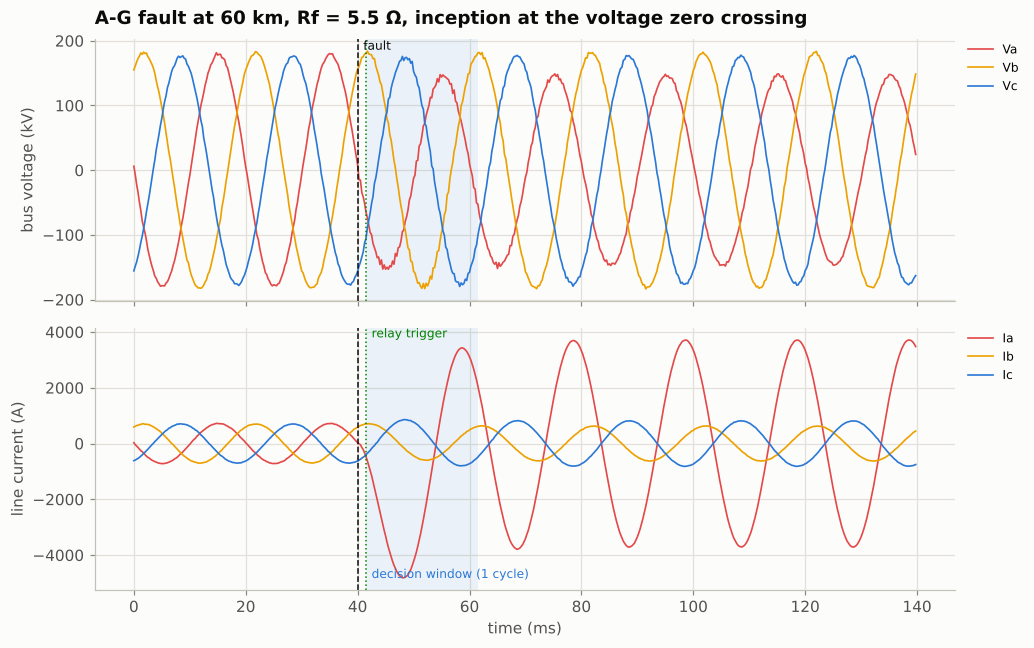

In [2]:
spec = FaultSpec(kind="AG", distance_km=60, r_arc=0.5, r_ground=5.0, inception_deg=90.0)
rec = add_noise(simulate(spec, system, post_cycles=5), 40.0, seed=1)
an = analyse_record(rec, decision_cycles=1.0)
print("disturbance detector tripped at sample", an.trigger_index, f"= {(an.trigger_index - rec.fault_index) / system.fs * 1e3:.2f} ms after the fault")
plot_waveforms(rec, "A-G fault at 60 km, Rf = 5.5 Ω, inception at the voltage zero crossing", trigger=an.trigger_index, decision_end=an.trigger_index + N);

The dashed line is the fault instant, the dotted line the trigger of the delta-current detector (every
sample compared with the sample one cycle earlier); the shaded band is the one-cycle DFT window the relay
decides on. Note the DC offset of the phase-A current — the first peak is much larger than the steady
fault current.

## 2. Does the simulator agree with the textbook?

With the remote source removed (radial feed) and a bolted fault, the fault currents must follow the
hand formulas: I₃ϕ = E / Z₁, I_AG = 3E / (Z₁ + Z₂ + Z₀) with Z₂ = Z₁, I_BC = √3 E / (Z₁ + Z₂).

In [3]:
radial = SystemParams(r_sc_mva=1e-3, e_r_pu=0.0, delta_deg=0.0)
rows = []
for kind, d in [("ABC", 20), ("ABC", 60), ("AG", 20), ("AG", 60), ("BC", 40)]:
    r = simulate(FaultSpec(kind=kind, distance_km=d, r_arc=1e-4, r_ground=1e-4), radial, post_cycles=8)
    I = dft_phasor(r.i, r.fault_index + 6 * N, N)
    z = sequence_impedances(radial, d)
    E = radial.v_phase_peak
    expected = {"ABC": E / abs(z["Z1_total"]), "AG": 3 * E / abs(2 * z["Z1_total"] + z["Z0_total"]), "BC": np.sqrt(3) * E / abs(2 * z["Z1_total"])}[kind]
    measured = {"ABC": abs(I).mean(), "AG": abs(I[0]), "BC": abs(I[1])}[kind]
    rows.append({"fault": kind, "distance km": d, "formula (A peak)": expected, "simulated (A peak)": measured, "error %": 100 * (measured / expected - 1)})
pd.DataFrame(rows).round(2)

,fault,distance km,formula (A peak),simulated (A peak),error %
0,ABC,20,10108.88,10107.83,-0.01
1,ABC,60,5288.56,5290.86,0.04
2,AG,20,7747.36,7735.53,-0.15
3,AG,60,3575.60,3563.73,-0.33
4,BC,40,6014.10,6018.78,0.08


## 3. Symmetrical components and the phase-selection angles

From the phasors of the decision window: the Fortescue components, the superimposed positive-sequence
current ΔI₁ = I₁ − I₁(pre-fault), and the two selector angles. For an A-G fault the boundary conditions give
I₁ = I₂ = I₀ at the fault, so ∠(I₂/ΔI₁) ≈ 0° and ∠(I₂/I₀) ≈ 0°.

sequence currents (A peak): I0 = 1161, I1 = 1734, I2 = 1288, dI1 = 1284
angle(I2 / dI1) = +0.2 deg,  angle(I2 / I0) = -0.2 deg
residual current / largest phase current = 0.85


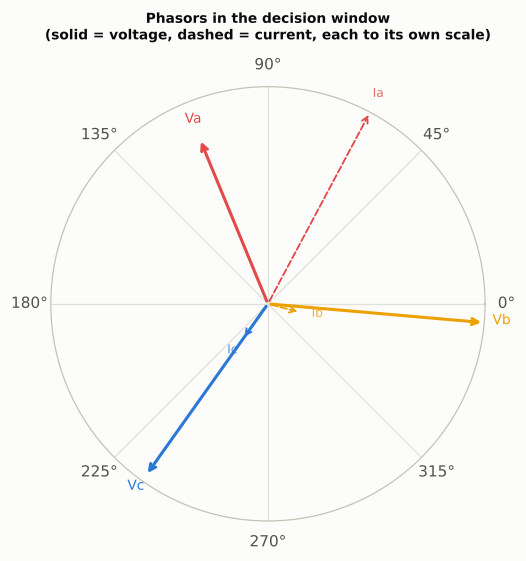

In [4]:
f = an.features
print("sequence currents (A peak): I0 = %.0f, I1 = %.0f, I2 = %.0f, dI1 = %.0f" % (abs(an.seq_I[0]), abs(an.seq_I[1]), abs(an.seq_I[2]), abs(an.dI1)))
print("angle(I2 / dI1) = %+.1f deg,  angle(I2 / I0) = %+.1f deg" % (np.degrees(np.arctan2(f["sin_a21"], f["cos_a21"])), np.degrees(np.arctan2(f["sin_a20"], f["cos_a20"]))))
print("residual current / largest phase current = %.2f" % f["ires"])
plot_phasors(an.V, an.I, title="Phasors in the decision window");

Now the same angle for every class — one clean fault of each type at 45 km. The table is the whole
phase-selection logic: six sectors of ∠(I₂/ΔI₁), residual current for the ground flag, no I₂ at all for a
balanced event.

In [5]:
rows = []
for kind in CLASSES:
    s = FaultSpec(kind=kind, distance_km=45.0, r_arc=0.3, r_ground=2.0, inception_deg=30.0, load_step_mw=100.0 if kind == "none" else 0.0)
    ff = analyse_record(add_noise(simulate(s, system), 40.0, seed=2), 1.0).features
    rows.append({"class": kind, "type": GROUPS[kind], "angle(I2/dI1) deg": np.degrees(np.arctan2(ff["sin_a21"], ff["cos_a21"])),
                 "angle(I2/I0) deg": np.degrees(np.arctan2(ff["sin_a20"], ff["cos_a20"])), "|I2|/|dI1|": ff["r_i2_di1"], "residual ratio": ff["ires"],
                 "I1 rise": ff["ri1"], "sequence rule": sequence_rule(ff), "overcurrent rule": magnitude_rule(ff)})
pd.DataFrame(rows).set_index("class").round(2)

,type,angle(I2/dI1) deg,angle(I2/I0) deg,|I2|/|dI1|,residual ratio,I1 rise,sequence rule,overcurrent rule
class,,,,,,,,
none,no fault,-153.94,28.71,0.03,0.02,1.30,none,ABC
AG,LG,-0.24,-0.17,1.00,0.92,2.25,AG,AG
BG,LG,120.21,-119.99,1.00,0.93,2.81,BG,BG
CG,LG,-119.90,119.85,1.00,0.94,2.67,CG,CG
AB,LL,60.63,-154.73,1.00,0.02,4.43,AB,AB
BC,LL,-179.73,72.15,1.00,0.00,5.24,BC,BC
CA,LL,-60.87,143.18,1.00,0.02,4.64,CA,CA
ABG,LLG,60.02,120.32,0.66,0.62,5.26,ABG,ABG
BCG,LLG,178.67,-6.32,0.76,0.42,5.91,BCG,BCG


## 4. The decision space of the whole test set

Every one of the 3,300 test events (features saved by `run_experiments.py`), coloured by its true class.
Left: ground faults in the plane of the two angles — single-phase faults sit at 0°, ±120° on both axes,
double-line-to-ground faults keep their ∠(I₂/ΔI₁) sector but drift along ∠(I₂/I₀) as the ground
resistance grows. Right: phase-to-phase faults at 180°, ±60°, three-phase faults with no negative sequence.

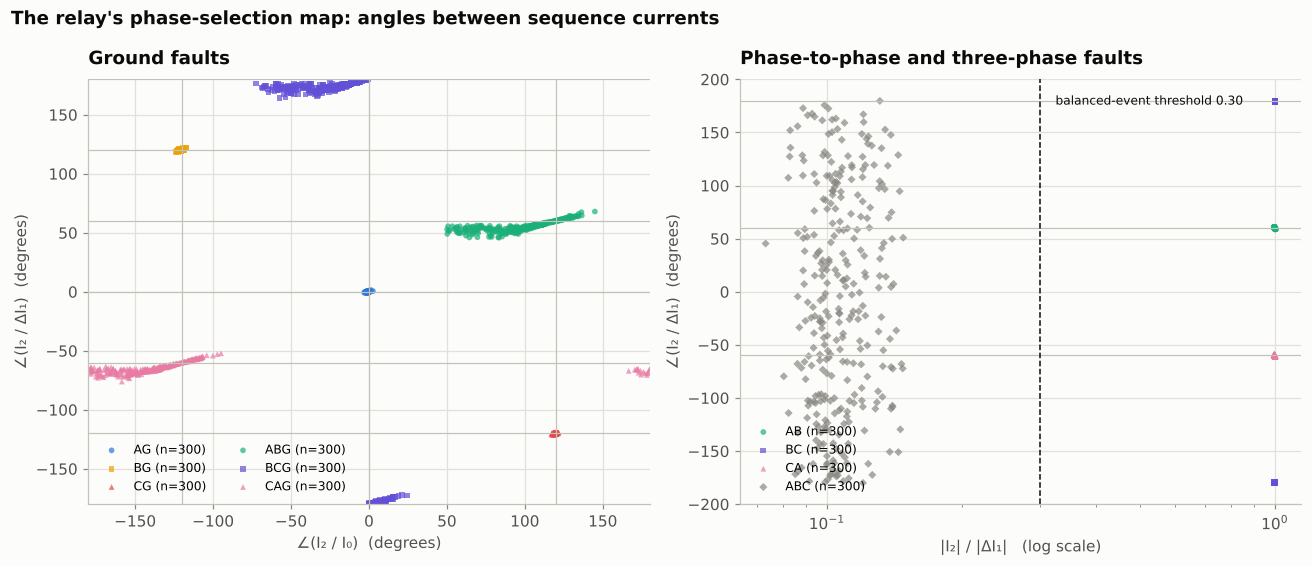

In [6]:
test = pd.read_csv(ROOT / "data" / "events_test.csv")
X_test, y_test = test[feature_names()], test["label"].to_numpy()
plot_sequence_angle_map(X_test, y_test);

## 5. Rules versus trained models on the test set

In [7]:
import joblib
from tlf.models import decode
bundle = joblib.load(ROOT / "models" / "classifiers.joblib")
preds = {"Overcurrent rule": apply_rule(magnitude_rule, X_test), "Sequence-angle relay logic": apply_rule(sequence_rule, X_test)}
for name, pipe in bundle["models"].items():
    preds[name] = decode(pipe.predict(X_test))
pd.DataFrame({n: summarise(y_test, p) for n, p in preds.items()}).T.round(4)

,accuracy,macro_f1,group_accuracy,detection_accuracy,missed_faults,false_trips,n
Overcurrent rule,0.9824,0.9823,0.9824,0.9824,0.0,58.0,3300.0
Sequence-angle relay logic,1.0000,1.0000,1.0000,1.0000,0.0,0.0,3300.0
k-Nearest Neighbours,0.9982,0.9982,0.9982,1.0000,0.0,0.0,3300.0
Neural Network,0.9994,0.9994,0.9994,1.0000,0.0,0.0,3300.0
Random Forest,1.0000,1.0000,1.0000,1.0000,0.0,0.0,3300.0
Gradient Boosting,1.0000,1.0000,1.0000,1.0000,0.0,0.0,3300.0


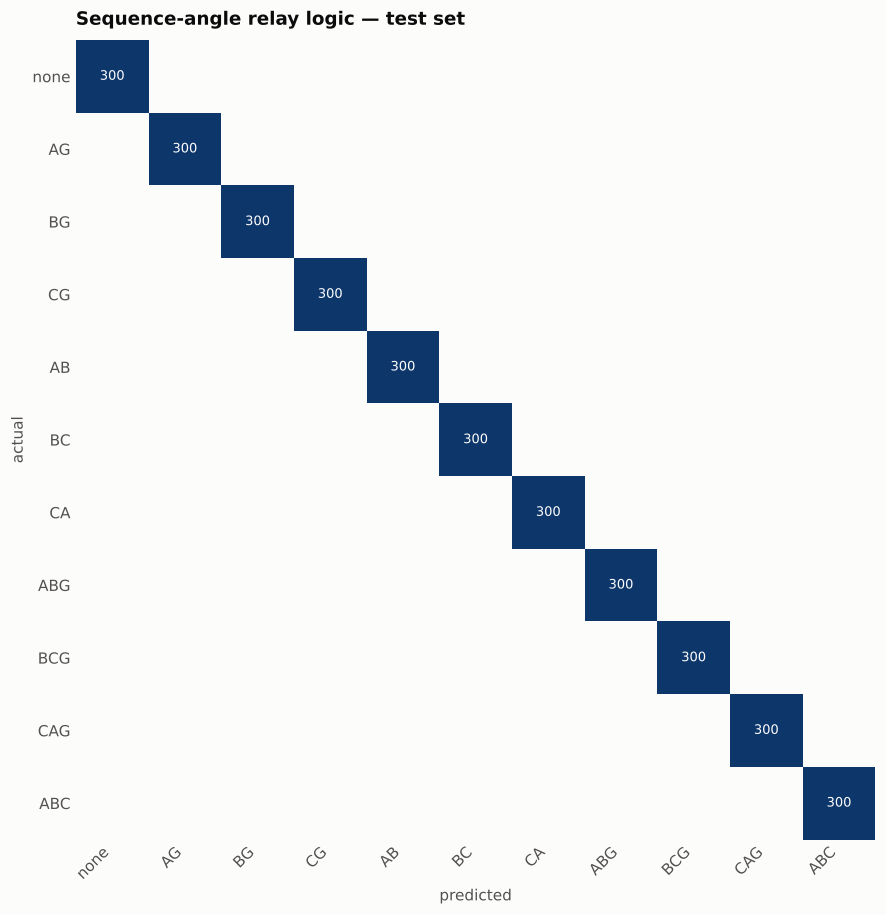

In [8]:
plot_confusion(confusion(y_test, preds["Sequence-angle relay logic"]), title="Sequence-angle relay logic — test set");

Where is the rule wrong? On the test set nowhere; on the 6,600 training events exactly once — a
double-line-to-ground fault at the far end through 32 Ω of ground resistance, whose residual current at
the relay (5.7 % of the phase current) is just under the 6 % ground pick-up because most of its
zero-sequence current flows in from the remote end. The cell lists every misclassified event of both sets.

In [9]:
train = pd.read_csv(ROOT / "data" / "events_train.csv")
cols = ["label", "distance_km", "r_arc", "r_ground", "load_step_mw", "delta_deg", "ires", "r_i2_di1", "zmag_ab"]
rows = []
for name, df in [("train", train), ("test", test)]:
    p = apply_rule(sequence_rule, df[feature_names()])
    wrong = p != df["label"].to_numpy()
    e = df.loc[wrong, cols].copy()
    e.insert(0, "set", name)
    e["predicted"] = p[wrong]
    rows.append(e)
pd.concat(rows).round(3)

,set,label,distance_km,r_arc,r_ground,load_step_mw,delta_deg,ires,r_i2_di1,zmag_ab,predicted
2979,train,CAG,97.731,0.026,31.901,0.0,11.434,0.057,0.964,3.143,CA


## 6. Fault location

The reactance method reads the distance from the imaginary part of the loop impedance; Takagi projects on
the superimposed current to cancel the effect of fault resistance with remote infeed. Both use the window
ending 3 cycles after the trigger, when the DC offset has decayed. Try a bolted fault and a resistive one.

In [10]:
rows = []
for d, r_arc, r_g in [(60, 1e-4, 1e-4), (60, 0.5, 5.0), (60, 1.0, 30.0), (90, 1.0, 30.0)]:
    r = add_noise(simulate(FaultSpec(kind="AG", distance_km=d, r_arc=r_arc, r_ground=r_g, inception_deg=20.0), system, post_cycles=5), 40.0, seed=3)
    a3 = analyse_record(r, 3.0)
    rows.append({"true km": d, "Rf (ohm)": r_arc + r_g, "reactance km": reactance_distance_km(a3, "AG", system), "Takagi km": takagi_distance_km(a3, "AG", system)})
pd.DataFrame(rows).round(2)

,true km,Rf (ohm),reactance km,Takagi km
0,60,0.0,59.30,59.32
1,60,5.5,57.15,58.86
2,60,31.0,50.13,58.64
3,90,31.0,63.93,85.27


## 7. The full experiment

All numbers of the README come from `reports/metrics.json`, written by `scripts/run_experiments.py`.

In [11]:
import json
m = json.loads((ROOT / "reports" / "metrics.json").read_text())
print("events: train %d, test %d, unseen system %d; features %d; best ML model: %s" % (m["n_train"], m["n_test"], m["n_unseen"], m["n_features"], m["best_ml"]))
display(pd.DataFrame(m["test"]).T[["accuracy", "macro_f1", "detection_accuracy", "missed_faults", "false_trips"]].round(4))
print("unseen system accuracy:"); display(pd.DataFrame(m["unseen_system"]).T[["accuracy"]].round(4))
print("accuracy versus decision time (cycles after trigger):"); display(pd.DataFrame(m["decision_time"]).T.round(3))
print("accuracy versus SNR:"); display(pd.DataFrame(m["noise"]).T.round(3))
print("fault location (km):"); display(pd.DataFrame(m["location"]).T.round(2))

events: train 6600, test 3300, unseen system 2200; features 58; best ML model: Random Forest
unseen system accuracy:
accuracy versus decision time (cycles after trigger):
accuracy versus SNR:
fault location (km):


,accuracy,macro_f1,detection_accuracy,missed_faults,false_trips
Overcurrent rule,0.9824,0.9823,0.9824,0.0,58.0
Sequence-angle relay logic,1.0000,1.0000,1.0000,0.0,0.0
k-Nearest Neighbours,0.9982,0.9982,1.0000,0.0,0.0
Neural Network,0.9994,0.9994,1.0000,0.0,0.0
Random Forest,1.0000,1.0000,1.0000,0.0,0.0
Gradient Boosting,1.0000,1.0000,1.0000,0.0,0.0


,accuracy
Overcurrent rule,0.9795
Sequence-angle relay logic,1.0000
k-Nearest Neighbours,0.9968
Neural Network,0.9964
Random Forest,1.0000
Gradient Boosting,1.0000


,Overcurrent rule,Sequence-angle relay logic,Random Forest (trained at this time)
0.25,0.752,0.757,0.998
0.5,0.936,0.902,1.000
0.75,0.986,0.999,1.000
1.0,0.982,1.000,1.000
1.5,0.982,1.000,1.000
2.0,0.983,1.000,1.000


,Overcurrent rule,Sequence-angle relay logic,k-Nearest Neighbours,Neural Network,Random Forest,Gradient Boosting
clean,0.982,1.000,0.999,0.999,1.000,1.000
40 dB,0.982,1.000,0.998,0.999,1.000,1.000
35 dB,0.982,1.000,0.998,0.999,1.000,1.000
30 dB,0.982,1.000,0.998,0.998,1.000,0.996
25 dB,0.977,0.994,0.988,0.989,0.993,0.984
20 dB,0.734,0.742,0.701,0.687,0.694,0.679


,mae_km,median_km,p90_km,max_km
Reactance method,1.71,0.70,3.60,56.67
Takagi method,0.68,0.46,1.55,8.10
ML regressor (gradient boosting),1.11,0.79,2.45,11.73


## 8. Take-aways

* The angles between the sequence currents are the physics of the fault; with them, relay settings derived
  from the measurement model classify 11 event types with zero errors on the test set one cycle after the
  trigger — and with one error in 6,600 training events, which shows where the margin ends.
* Machine learning on the same per-unit relay quantities matches that (100 %) and transfers to a line it
  never saw; it earns its place only at very early decision times, not by replacing the relay logic.
* Takagi's method — a 1982 closed-form formula using the superimposed current — locates faults better than
  a gradient-boosting regressor trained on 6,000 faults.
* Raw samples (the Kaggle dataset) give 87 %; a one-cycle window of relay quantities gives 100 %. The
  feature is the engineering.